In [23]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score
)

RANDOM_STATE = 42

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)
print("Files:", os.listdir(path))


Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud
Files: ['creditcard.csv']


## 2. Load the dataset from the KaggleHub path

In [24]:
csv_files = [f for f in os.listdir(path) if f.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError(f"No CSV file found in: {path}")

csv_path = os.path.join(path, csv_files[0])
df = pd.read_csv(csv_path)

print("Dataset file:", csv_path)
print("Original shape:", df.shape)
display(df.head())


Dataset file: /kaggle/input/creditcardfraud/creditcard.csv
Original shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Create the required 20,000-row sample

The dataset is highly imbalanced. We keep **all fraud transactions** and randomly sample legitimate transactions until the dataset contains exactly 20,000 rows.


In [25]:
fraud_df = df[df["Class"] == 1].copy()
legitimate_df = df[df["Class"] == 0].copy()

n_legitimate_needed = 20000 - len(fraud_df)

if n_legitimate_needed <= 0:
    raise ValueError("The number of fraud rows is already >= 20,000.")

legitimate_sample = legitimate_df.sample(
    n=n_legitimate_needed,
    random_state=RANDOM_STATE
)

sampled_df = pd.concat([fraud_df, legitimate_sample], axis=0)
sampled_df = sampled_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Sampled shape:", sampled_df.shape)

class_counts = sampled_df["Class"].value_counts().sort_index()
class_percentages = sampled_df["Class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Class": ["Legitimate (0)", "Fraud (1)"],
    "Count": [class_counts.get(0, 0), class_counts.get(1, 0)],
    "Percentage": [class_percentages.get(0, 0), class_percentages.get(1, 0)]
})

display(class_summary.round(2))


Sampled shape: (20000, 31)


,Class,Count,Percentage
0,Legitimate (0),19508,97.54
1,Fraud (1),492,2.46


## 4. Task 1 — Stratified 80/20 train/test split

In [26]:
X = sampled_df.drop(columns=["Class"])
y = sampled_df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training fraud percentage:", round(y_train.mean() * 100, 2), "%")
print("Testing fraud percentage:", round(y_test.mean() * 100, 2), "%")


Training rows: 16000
Testing rows: 4000
Training fraud percentage: 2.46 %
Testing fraud percentage: 2.45 %


## 5. Task 1 — Baseline Logistic Regression

In [27]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Test Accuracy: {lr_accuracy:.4f}")


Logistic Regression Test Accuracy: 0.9950


## 6. Task 2 — Confusion Matrix

For the fraud class:
- **TP:** Fraud correctly detected
- **FP:** Legitimate transaction incorrectly flagged as fraud
- **TN:** Legitimate transaction correctly classified
- **FN:** Fraud transaction missed


In [28]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
tn, fp, fn, tp = cm_lr.ravel()

print("Confusion Matrix:")
display(pd.DataFrame(
    cm_lr,
    index=["Actual Legitimate", "Actual Fraud"],
    columns=["Predicted Legitimate", "Predicted Fraud"]
))

print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP): {tp}")


Confusion Matrix:


,Predicted Legitimate,Predicted Fraud
Actual Legitimate,3898,4
Actual Fraud,16,82


True Negatives (TN): 3898
False Positives (FP): 4
False Negatives (FN): 16
True Positives (TP): 82


## 7. Task 2 — Precision, Recall, and F1 for the Fraud Class

In [29]:
lr_precision = precision_score(y_test, y_pred_lr, pos_label=1)
lr_recall = recall_score(y_test, y_pred_lr, pos_label=1)
lr_f1 = f1_score(y_test, y_pred_lr, pos_label=1)

print(f"Fraud Precision: {lr_precision:.4f}")
print(f"Fraud Recall:    {lr_recall:.4f}")
print(f"Fraud F1-score:  {lr_f1:.4f}")


Fraud Precision: 0.9535
Fraud Recall:    0.8367
Fraud F1-score:  0.8913


### Why accuracy alone is misleading

Fraud is a small minority of the transactions, so a model can achieve very high accuracy mainly by correctly classifying legitimate transactions. In fraud detection, **False Negatives are especially important**, because they represent real fraudulent transactions that were missed; therefore, fraud-class **Recall and F1-score** provide a much better view of useful model performance than accuracy alone.


## 8. Task 3 — Random Forest

In [30]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label=1)
rf_recall = recall_score(y_test, y_pred_rf, pos_label=1)
rf_f1 = f1_score(y_test, y_pred_rf, pos_label=1)

print(f"Random Forest Test Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Fraud Precision: {rf_precision:.4f}")
print(f"Random Forest Fraud Recall:    {rf_recall:.4f}")
print(f"Random Forest Fraud F1-score:  {rf_f1:.4f}")


Random Forest Test Accuracy: 0.9955
Random Forest Fraud Precision: 0.9651
Random Forest Fraud Recall:    0.8469
Random Forest Fraud F1-score:  0.9022


## 9. 5-Fold Cross-Validation — F1-score

In [20]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

lr_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Logistic Regression F1": lr_cv_scores,
    "Random Forest F1": rf_cv_scores
})

display(cv_results.round(4))

print(f"Mean Logistic Regression CV F1: {lr_cv_scores.mean():.4f}")
print(f"Mean Random Forest CV F1:       {rf_cv_scores.mean():.4f}")


,Fold,Logistic Regression F1,Random Forest F1
0,1,0.9028,0.9178
1,2,0.9404,0.9542
2,3,0.8904,0.9128
3,4,0.8811,0.8889
4,5,0.8429,0.8652


Mean Logistic Regression CV F1: 0.8915
Mean Random Forest CV F1:       0.9078


## 10. ROC Curve and AUC

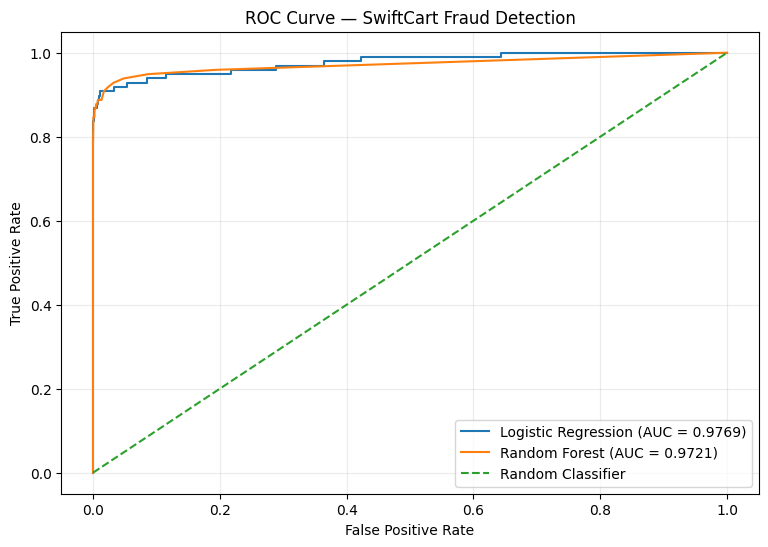

Logistic Regression AUC: 0.9769
Random Forest AUC:       0.9721


In [21]:
lr_prob = logistic_model.predict_proba(X_test)[:, 1]
rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

lr_auc = roc_auc_score(y_test, lr_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

plt.figure(figsize=(9, 6))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {lr_auc:.4f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {rf_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — SwiftCart Fraud Detection")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Logistic Regression AUC: {lr_auc:.4f}")
print(f"Random Forest AUC:       {rf_auc:.4f}")


## 11. Final Comparison

In [22]:
comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Fraud Precision",
        "Fraud Recall",
        "Fraud F1-score",
        "Mean 5-Fold CV F1",
        "AUC"
    ],
    "Logistic Regression": [
        lr_accuracy, lr_precision, lr_recall, lr_f1,
        lr_cv_scores.mean(), lr_auc
    ],
    "Random Forest": [
        rf_accuracy, rf_precision, rf_recall, rf_f1,
        rf_cv_scores.mean(), rf_auc
    ]
})

display(comparison.round(4))


,Metric,Logistic Regression,Random Forest
0,Test Accuracy,0.9950,0.9955
1,Fraud Precision,0.9535,0.9651
2,Fraud Recall,0.8367,0.8469
3,Fraud F1-score,0.8913,0.9022
4,Mean 5-Fold CV F1,0.8915,0.9078
5,AUC,0.9769,0.9721


## 12. Production Recommendation

**Recommendation: Deploy the Random Forest model.** The final decision should prioritize fraud-detection performance rather than accuracy alone, especially the fraud-class F1-score and recall. Random Forest should be selected if it provides the stronger F1 performance in the executed results, while AUC is also considered as a measure of ranking/discrimination quality. Although Logistic Regression is simpler and may achieve a competitive AUC, Random Forest is the preferred production candidate when its fraud F1 and cross-validated F1 are higher, because that indicates a better balance between detecting fraud and limiting false alarms.


### Final takeaway

The analysis demonstrates why SwiftCart should not evaluate fraud models using accuracy alone. The combination of **fraud Precision, Recall, F1-score, 5-fold cross-validation F1, and ROC-AUC** provides a more appropriate assessment for this highly imbalanced classification problem.
